dataset_2175_kin8nm.csv contains motion data of an 8-jointed robotic arm. Downloaded at: https://www.openml.org/search?type=data&sort=runs&id=189&status=active 

Further Information: https://www.openml.org/search?type=data&sort=runs&id=189&status=active

## Goal: Regression

In [1]:
%cd Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward/

/home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/feedforward


In [2]:
!dir

dataset_2175_kin8nm.csv		  logs
feedforward_accuracy_plots.ipynb  plots
feedforward_experiments.ipynb	  train_feedforward.py


In [ ]:
import numpy as np
import copy


In [4]:
import torch
torch.manual_seed(1234)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
file_path = "dataset_2175_kin8nm.csv"
data = np.loadtxt(file_path, delimiter=",", skiprows=1)

# Daten aufbereiten

### Shuffle, Train, Test

In [6]:
rng = np.random.default_rng(1234)
rng.shuffle(data)

In [ ]:
x_data = data[:, :-1]
y_data = data[:, -1]

train_fraction = 0.8
n_train = int(x_data.shape[0] * train_fraction)
x_train = x_data[:n_train]
y_train = y_data[:n_train]
x_test = x_data[n_train:]
y_test = y_data[n_train:]

###  Data Normalisation

In [8]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((6553, 8), (6553,), (1639, 8), (1639,))

In [ ]:
x_mean = np.mean(x_train, axis=0, keepdims=True)
y_mean = np.mean(y_train, keepdims=True)
x_std = np.std(x_train, axis=0, ddof=1, keepdims=True)
y_std = np.std(y_train, ddof=1, keepdims=True)

In [10]:
x_train = torch.tensor((x_train - x_mean) / x_std, dtype=torch.float32, device = device)
y_train = torch.tensor((y_train - y_mean) / y_std, dtype=torch.float32, device = device)
x_test = torch.tensor((x_test - x_mean) / x_std, dtype=torch.float32, device = device)
y_test = torch.tensor((y_test - y_mean) / y_std, dtype=torch.float32, device = device)


### Architecture
Block:
Linear $\to$ BatchNorm1d $\to$ ReLU $\to$ Dropout(0.1)

Overall:
|Inp|Hidden1|Hidden2|Hidden3|Out|
|---|---|---|---|---|
|8|256| 128| 64|1

Last Block no ReLU, Dropout

Lossfunktion: MSELoss

Batch Size: 64

Optimizer: SGD, AdamW, Muon (with Adam for 1D parameters)

In [58]:
class BatchNorm:
    def __init__(self, dim, momentum=0.1, eps=1e-5):
        self.eps = eps
        self.momentum = momentum

        self.scale = torch.ones((1, dim), dtype=torch.float32, device=device, requires_grad=True)
        self.shift = torch.zeros((1, dim), dtype=torch.float32, device=device, requires_grad=True)
        self.params = [self.scale, self.shift]

        self.running_mu_in = torch.zeros((1, dim), dtype=torch.float32, device=device)
        self.running_sigma_squared_in = torch.ones((1, dim), dtype=torch.float32, device=device)

        self.training = True

    def train(self):
        self.training = True
        return self

    def eval(self):
        self.training = False
        return self

    def __call__(self, x: torch.Tensor):
        if self.training:
            reduce_dims = [0] + list(range(2, x.dim()))
            
            sigma_squared, mu = torch.var_mean(x, dim=reduce_dims, keepdim=True, unbiased=False)
            
            x_normalized = (x - mu) / torch.sqrt(sigma_squared + self.eps)
            
            with torch.no_grad():
                self.running_mu_in = (1 - self.momentum) * self.running_mu_in + self.momentum * mu.detach()
                self.running_sigma_squared_in = (1 - self.momentum) * self.running_sigma_squared_in + self.momentum * sigma_squared.detach()
        else:
            x_normalized = (x - self.running_mu_in) / torch.sqrt(self.running_sigma_squared_in + self.eps)
        return self.scale * x_normalized + self.shift


class EfficientDropoutFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, p, training):
        ctx.p = p
        ctx.training = training
        if not training or p == 0.0:
            return x

        ctx.seed = torch.randint(0, 2**31 - 1, (1,), device=x.device).item()
        gen = torch.Generator(device=x.device).manual_seed(ctx.seed)
        
        mask = (torch.rand(x.shape, generator=gen, device=x.device) > p).to(x.dtype)
        return x * mask / (1.0 - p)

    @staticmethod
    def backward(ctx, grad_output):
        if not ctx.training or ctx.p == 0.0:
            return grad_output, None, None

        gen = torch.Generator(device=grad_output.device).manual_seed(ctx.seed)
        mask = (torch.rand(grad_output.shape, generator=gen, device=grad_output.device) > ctx.p).to(grad_output.dtype)
        grad_input = (grad_output * mask) / (1.0 - ctx.p)
        return grad_input, None, None


class EfficientDropout:
    def __init__(self, p=0.2):
        self.p = p
        self.training = True

    def train(self):
        self.training = True
        return self

    def eval(self):
        self.training = False
        return self

    def __call__(self, x: torch.Tensor):
        return EfficientDropoutFunction.apply(x, self.p, self.training)

class SGD:
    """SGD with weight decay"""
    def __init__(self, params, lr=0.0241, weight_decay=0.00495, lr_decay=0.99):
        self.params = list(params)
        self.initial_lr = lr
        self.lr = lr
        self.lr_decay = lr_decay
        self.weight_decay = weight_decay

    def step(self):
        with torch.no_grad():
            for p in self.params:
                if p.grad is None:
                    continue
                p.mul_(1 - self.lr * self.weight_decay)
                p.sub_(p.grad, alpha=self.lr)
            self.lr *= self.lr_decay
        return self.params

class AdamW:
    def __init__(self, params, lr=0.00985, beta1=0.9, beta2=0.999, weight_decay=0.0904, lr_decay=1.0, eps=1e-8):
        self.params = list(params)
        self.beta1 = beta1
        self.beta2 = beta2
        self.lr = lr
        self.weight_decay = weight_decay
        self.lr_decay = lr_decay
        self.eps = eps

        self.v1 = [torch.zeros_like(p) for p in params]
        self.v2 = [torch.zeros_like(p) for p in params]
        self.step_i = 0


    def step(self):
        self.step_i += 1
        with torch.no_grad():
            for p_i, p in enumerate(self.params):
                if p.grad is None:
                    continue

                grad = p.grad

                self.v1[p_i] = (self.beta1) * self.v1[p_i] + (1 - self.beta1) * grad
                self.v2[p_i] = (self.beta2) * self.v2[p_i] + (1 - self.beta2) * (grad ** 2)

                v1_pi_head = self.v1[p_i] / (1 - self.beta1 ** self.step_i)
                v2_pi_head = self.v2[p_i] / (1 - self.beta2 ** self.step_i)
                update = self.lr * v1_pi_head / (torch.sqrt(v2_pi_head) + self.eps)

                p.sub_(self.lr * self.weight_decay * p + update)
                if self.step_i == 900 and p.shape == (32, 16):
                    self.logged_adam_momentum = v1_pi_head
                    self.logged_adam_update = update
            self.lr *= self.lr_decay
        return self.params


def newtonschulz(G, steps=5, eps=1e-7):
    assert G.ndim == 2
    a, b, c = (3.4445, -4.7750, 2.0315)
    
    X = G.bfloat16()
    X /= (X.norm() + eps)
    
    if G.size(0) > G.size(1):
        X = X.T
        
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * A @ A
        X = a * X + B @ X
        
    if G.size(0) > G.size(1):
        X = X.T
        
    return X.to(G.dtype)

def zeropower_via_newtonschulz6_cesista(G):
    assert len(G.shape) == 2
    abc_cesista = [
        (3.9947, -8.6494, 4.7603),
        (3.9943, -8.6482, 4.7597),
        (3.9702, -8.5041, 4.6666),
        (3.6505, -7.0837, 3.7913),
        (2.6632, -3.9414, 2.0658),
        (2.2803, -2.2275, 0.9689),
    ]
    X = G.bfloat16()
    if G.size(0) > G.size(1):
        X = X.T

    X = X / (X.norm() + 1e-7)
    for (a, b, c) in abc_cesista:
        A = X @ X.T
        B = b * A + c * A @ A
        X = a * X + B @ X

    if G.size(0) > G.size(1):
        X = X.T
    return X.to(G.dtype)

class Muon:
    def __init__(self, params, lr=0.0149, adam_lr=0.000545, beta=0.9, adam_beta1=0.9, adam_beta2=0.999, weight_decay=0.000686, lr_decay=1.0, eps=1e-8):
        self.lr = lr
        self.weight_decay = weight_decay
        self.lr_decay = lr_decay
        self.eps = eps
        self.beta = beta

        self.params = list(params) 
        self.linear_params = []
        self.muon_momenta = []
        self.adam_params = []
        
        for p in self.params:
            if p.dim() == 2:
                self.linear_params.append(p)
                self.muon_momenta.append(torch.zeros_like(p))
            else:
                self.adam_params.append(p)
                
        self.adam_instance = AdamW(self.adam_params, adam_lr, adam_beta1, adam_beta2, weight_decay, lr_decay, eps)

        self.step_i = 0 

    def step(self):
        self.step_i += 1
        self.adam_instance.step()
        
        with torch.no_grad():
            for p_i, p in enumerate(self.linear_params):
                if p.grad is None:
                    continue
                
                self.muon_momenta[p_i] = self.beta * self.muon_momenta[p_i] + (1 - self.beta) * p.grad
                update = zeropower_via_newtonschulz6_cesista(self.muon_momenta[p_i])
                scale = max(1, p.size(0) / p.size(1)) ** 0.5
                update.mul_(scale)
                p.mul_(1 - self.lr * self.weight_decay)
                p.sub_(update, alpha=self.lr)

                if self.step_i == 900 and p.shape == (32, 16):
                    self.logged_muon_momentum = self.muon_momenta[p_i]
                    self.logged_muon_update = update

            self.lr *= self.lr_decay

        return self.params



In [47]:
class Feedforward:
    def __init__(self, x_test, y_test, device, dropout_rate=0.2):
        self.device = device
        self.x_test = x_test
        self.y_test = y_test
        
        d_in = 8
        h1, h2, h3 = 256, 32, 16
        d_out = 1
        
        self.M1 = torch.empty((d_in, h1), dtype=torch.float32, device=self.device)
        self.M2 = torch.empty((h1, h2), dtype=torch.float32, device=self.device)
        self.M3 = torch.empty((h2, h3), dtype=torch.float32, device=self.device)
        self.M4 = torch.empty((h3, d_out), dtype=torch.float32, device=self.device)
        
        self.b4 = torch.zeros((1, d_out), dtype=torch.float32, device=self.device)
        
        self.bn1 = BatchNorm(h1)
        self.bn2 = BatchNorm(h2)
        self.bn3 = BatchNorm(h3)
        
        self.drop1 = EfficientDropout(p=dropout_rate)
        self.drop2 = EfficientDropout(p=dropout_rate)
        self.drop3 = EfficientDropout(p=dropout_rate)
        
        self.weight_matrices = [self.M1, self.M2, self.M3, self.M4]
        self.layers = [self.bn1, self.bn2, self.bn3, self.drop1, self.drop2, self.drop3]

        self.params = self.weight_matrices + [self.b4] + self.bn1.params + self.bn2.params + self.bn3.params
        
        self.relu = torch.nn.ReLU()
        self.loss_function = torch.nn.MSELoss()
        
        for p in self.params:
            p.requires_grad_()
            
        for m in self.weight_matrices[:-1]:
            torch.nn.init.kaiming_uniform_(m, nonlinearity="relu")
            
        torch.nn.init.kaiming_uniform_(self.weight_matrices[-1], nonlinearity="linear")

    def forward(self, x):
        y = self.relu(self.bn1(x @ self.M1))
        y = self.drop1(y)

        y = self.relu(self.bn2(y @ self.M2))
        y = self.drop2(y)

        y = self.relu(self.bn3(y @ self.M3))
        y = self.drop3(y)

        y = y @ self.M4 + self.b4
        return y.view(-1)

    def eval_test_error(self):
        for layer in self.layers:
            layer.eval()
            
        with torch.no_grad():
            y_pred = self.forward(self.x_test)
            loss = self.loss_function(self.y_test, y_pred)
            
        for layer in self.layers:
            layer.train()
            
        return loss.item()

In [59]:
def train(model, optimizer, seed, batch_size=64, steps=1000, intermediate_losses=True):
    gen = torch.Generator(device).manual_seed(seed)
    for i in range(steps):
        i_rand = torch.randperm(n_train, generator=gen, device=device)[:batch_size]
        x_rand = x_train[i_rand]
        y_rand = y_train[i_rand]

        y_pred = model.forward(x_rand)

        loss = model.loss_function(y_pred, y_rand)

        loss.backward()
        
        if i % 99 == 0 and intermediate_losses:
            print(loss)
                
        with torch.no_grad():
            optimizer.step()
            
            for p in model.params:
                p.grad.zero_()

    return model

In [60]:

batch_size = 64
n_runs = 1
losses = [[], [], []]

for step in range(n_runs):
    base_model = Feedforward(x_test, y_test, device, dropout_rate=0)
    # to assure same initialization: one copy for each optimizer. Dropout is independently random anyways
    models = [base_model, copy.deepcopy(base_model), copy.deepcopy(base_model)]

    for i, (model, optim_class) in enumerate(zip(models, [Muon])):#[SGD, AdamW, Muon])):
        optimizer = optim_class(model.params)

        # only training samples are seeded, not the dropout
        train(model, optimizer, seed=step, steps=1000)

        losses[i].append(model.eval_test_error())

losses, [sum(loss) for loss in losses]

tensor(15.9659, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1584, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.3266, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1584, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1223, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.2443, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1282, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1365, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1364, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.1315, device='cuda:0', grad_fn=<MseLossBackward0>)
tensor(0.3685, device='cuda:0', grad_fn=<MseLossBackward0>)


([[0.11164843291044235], [], []], [0.11164843291044235, 0, 0])

In [50]:
logged_adamw_momentum = optimizer.logged_adam_momentum
logged_adamw_update = optimizer.logged_adam_update

In [61]:
logged_muon_momentum = optimizer.logged_muon_momentum
logged_muon_update = optimizer.logged_muon_update

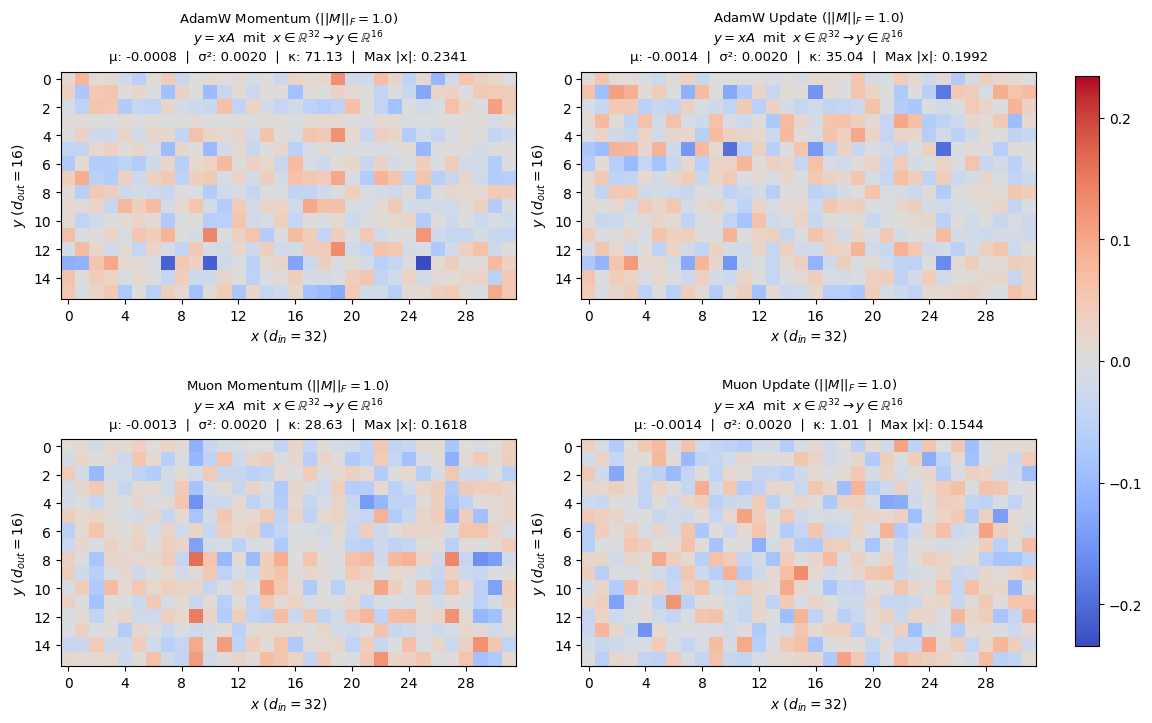

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import torch


def _to_numpy(tensor_or_array):
    if isinstance(tensor_or_array, torch.Tensor):
        return tensor_or_array.detach().cpu().numpy()
    return np.array(tensor_or_array)


def compute_matrix_stats(M):
    s = np.linalg.svd(M, compute_uv=False)
    cond_num = s[0] / s[-1] if s[-1] > 1e-12 else np.nan
    return {
        "mean": np.mean(M),
        "var": np.var(M),
        "cond": cond_num,
        "max_abs": np.max(np.abs(M)),
    }


def heatplot(
    adamw_momentum,
    adamw_update,
    muon_momentum,
    muon_update,
    d_in=32,
    d_out=16,
):
    adamw_momentum = _to_numpy(adamw_momentum)
    adamw_update = _to_numpy(adamw_update)
    muon_momentum = _to_numpy(muon_momentum)
    muon_update = _to_numpy(muon_update)

    matrices = {
        "AdamW Momentum": (adamw_momentum / np.linalg.norm(adamw_momentum)).T,
        "AdamW Update": (adamw_update / np.linalg.norm(adamw_update)).T,
        "Muon Momentum": (muon_momentum / np.linalg.norm(muon_momentum)).T,
        "Muon Update": (muon_update / np.linalg.norm(muon_update)).T,
    }

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 7.5))
    max_val = max(np.max(np.abs(m)) for m in matrices.values())
    cmap = "coolwarm"

    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]
    last_im = None

    for (title, M), (r, c) in zip(matrices.items(), positions):
        ax = axes[r, c]
        stats = compute_matrix_stats(M)

        last_im = ax.imshow(M, cmap=cmap, vmin=-max_val, vmax=max_val)

        ax.set_title(
            f"{title} ($||M||_F = 1.0$)\n"
            f"$y = x A$  mit  $x \\in \\mathbb{{R}}^{{{d_in}}} \\to y \\in \\mathbb{{R}}^{{{d_out}}}$\n"
            f"μ: {stats['mean']:.4f}  |  σ²: {stats['var']:.4f}  |  "
            f"κ: {stats['cond']:.2f}  |  Max |x|: {stats['max_abs']:.4f}",
            fontsize=9.5,
            pad=8,
        )

        ax.set_xlabel(f"$x$ ($d_{{in}} = {d_in}$)")
        ax.set_ylabel(f"$y$ ($d_{{out}} = {d_out}$)")

        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout(rect=[0, 0, 0.88, 1])

    cax = fig.add_axes([0.90, 0.12, 0.02, 0.76])
    cbar = fig.colorbar(last_im, cax=cax)
    cbar.ax.tick_params(labelsize=10)

    plt.show()


heatplot(
    logged_adamw_momentum,
    logged_adamw_update,
    logged_muon_momentum,
    logged_muon_update,
    d_in=32,
    d_out=16,
)

In [45]:
average_losses = [sum(loss)/n_runs for loss in losses]
average_losses

[0.33020180463790894, 0.12174316793680191, 0.12974150329828263]

### Average Losses for n_runs=20, 1000 steps:


|SGD|AdamW|Muon|
|------|------|------|
|0.4134|0.1333|0.1261|

In [16]:
# todo: losskurven dokumentieren und plotten wie in anderem Skript

# Hyperparameter tuning

In [ ]:
import optuna

total_steps = 1000
# 10 Epochs on the training set are 1030 steps
dropout_rate = 0.2

def objective(trial):
    #sgd_lr = trial.suggest_float("sgd_lr", 1e-3, 1e-1, log=True)
    muon_lr = trial.suggest_float("muon_lr", 1e-3, 1e-1, log=True)
    adam_lr = trial.suggest_float("adam_lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-1, log=True)

    d_in = 8
    h1, h2, h3 = 256, 128, 64
    d_out = 1

    M1 = torch.empty((d_in, h1), dtype=torch.float32, device=device, requires_grad=True)
    M2 = torch.empty((h1, h2), dtype=torch.float32, device=device, requires_grad=True)
    M3 = torch.empty((h2, h3), dtype=torch.float32, device=device, requires_grad=True)
    M4 = torch.empty((h3, d_out), dtype=torch.float32, device=device, requires_grad=True)

    b4 = torch.zeros((1, d_out), dtype=torch.float32, device=device, requires_grad=True)

    bn1 = BatchNorm(h1)
    bn2 = BatchNorm(h2)
    bn3 = BatchNorm(h3)

    drop1 = EfficientDropout(p=dropout_rate)
    drop2 = EfficientDropout(p=dropout_rate)
    drop3 = EfficientDropout(p=dropout_rate)

    weight_matrizes = [M1, M2, M3, M4]

    for m in weight_matrizes[:-1]:
        torch.nn.init.kaiming_uniform_(m, nonlinearity="relu")
    torch.nn.init.kaiming_uniform_(weight_matrizes[-1], nonlinearity="linear")

    params = weight_matrizes + [b4] + bn1.params + bn2.params + bn3.params
    layers = [bn1, bn2, bn3, drop1, drop2, drop3]
    #optimizer = SGD(params, lr=sgd_lr, weight_decay=weight_decay)
    #optimizer = AdamW(params, lr=adam_lr, weight_decay=weight_decay)
    optimizer = Muon(params, lr=muon_lr, adam_lr=adam_lr, weight_decay=weight_decay)
    relu = torch.nn.ReLU()
    loss_function = torch.nn.MSELoss()

    def model_call(x):
        y = relu(bn1(x @ M1))
        y = drop1(y)
        y = relu(bn2(y @ M2))
        y = drop2(y)
        y = relu(bn3(y @ M3))
        y = drop3(y)
        y = y @ M4 + b4
        return y.view(-1)

    def eval_test_error():
        for layer in layers:
            layer.eval()
            
        with torch.no_grad():
            y_pred = model_call(x_test)
            loss = loss_function(y_test, y_pred)
            
        for layer in layers:
            layer.train()
            
        return loss.item()


    n_samples = len(x_train)
    for _ in range(total_steps):

        indices = torch.randint(0, n_samples, (batch_size,), device=device)
        X_batch = x_train[indices]
        y_batch = y_train[indices]
        
        for p in params:
            if p.grad is not None:
                p.grad.detach_()
                p.grad.zero_()

        y_pred = model_call(X_batch)
        loss = loss_function(y_pred, y_batch)
        

        loss.backward()
        optimizer.step()

    return eval_test_error()

In [24]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30) # Testet 30 Kombinationen

print("Beste Parameter:", study.best_params)

[I 2026-07-31 13:20:52,848] A new study created in memory with name: no-name-9760a847-c2a3-4414-9be4-27d2785c694f
[I 2026-07-31 13:21:10,983] Trial 0 finished with value: 1.036676049232483 and parameters: {'muon_lr': 0.09871626751069429, 'adam_lr': 0.007492475950558256, 'weight_decay': 0.003417339689676287}. Best is trial 0 with value: 1.036676049232483.
[I 2026-07-31 13:21:29,108] Trial 1 finished with value: 0.22402739524841309 and parameters: {'muon_lr': 0.0013907908332760938, 'adam_lr': 0.0005195706980619734, 'weight_decay': 0.05586834053232842}. Best is trial 1 with value: 0.22402739524841309.
[I 2026-07-31 13:21:47,214] Trial 2 finished with value: 0.12480154633522034 and parameters: {'muon_lr': 0.009536415334053994, 'adam_lr': 0.0012625689581497548, 'weight_decay': 0.00035366537064679545}. Best is trial 2 with value: 0.12480154633522034.
[I 2026-07-31 13:22:05,276] Trial 3 finished with value: 0.13588732481002808 and parameters: {'muon_lr': 0.008607254385377848, 'adam_lr': 0.000

Beste Parameter: {'muon_lr': 0.010697601236698709, 'adam_lr': 0.000795594876518164, 'weight_decay': 0.005896378593402303}


Best found parameters for:

1. Muon, 1000 steps (exact numbers accidently deleted):  {'muon_lr': 0.0149, 'adam_lr': 0.000545, 'weight_decay': 0.000686}

2. AdamW, 1000 steps: {'adam_lr': 0.009853006362846941, 'weight_decay': 0.09039039358008569}

3. SGD, 1000 steps: {'sgd_lr': 0.02408185208212524, 'weight_decay': 0.004953799637031042}

Warning: test-set instead of a validation-set was used, but probably not problematic since it is just used for learning rates and weight decay

In [23]:
!nvidia-smi

Fri Jul 31 13:20:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.163.01             Driver Version: 550.163.01     CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          Off |   00000000:21:00.0 Off |                    0 |
| N/A   60C    P0            236W /  250W |   35553MiB /  40960MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----